In [2]:
import sys, platform, random, time, json, copy, math, os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.optim import AdamW
from torch.utils.data import Dataset, DataLoader, ConcatDataset
from torchvision import models, transforms
from torchvision.datasets import OxfordIIITPet
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report, confusion_matrix
)

print("Python:", sys.version.split()[0])
print("Architecture:", platform.machine())
print("PyTorch:", torch.__version__)
print("Torchvision:", __import__("torchvision").__version__)
print("MPS available:", torch.backends.mps.is_available())
print("CUDA available:", torch.cuda.is_available())

Python: 3.14.5
Architecture: arm64
PyTorch: 2.14.1
Torchvision: 0.29.1
MPS available: True
CUDA available: False


In [3]:
ROOT = Path.cwd()
DATA_DIR = ROOT / "data" / "oxford_pet"
CHECKPOINT_DIR = ROOT / "checkpoints"
RESULTS_DIR = ROOT / "results"
SPLIT_PATH = ROOT / "data" / "splits_seed42.json"

for folder in (DATA_DIR, CHECKPOINT_DIR, RESULTS_DIR, SPLIT_PATH.parent):
    folder.mkdir(parents=True, exist_ok=True)

SEED = 42
NUM_CLASSES = 10
BATCH_SIZE = 32
EPOCHS = 20
PATIENCE = 3
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 0

CLASS_NAMES = [
    "Abyssinian", "Bengal", "Birman", "Bombay", "British Shorthair",
    "Beagle", "Boxer", "Chihuahua", "German Shorthaired", "Pug"
]
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

if torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()
print("Device:", DEVICE)
print("Data:", DATA_DIR)
print("Checkpoints:", CHECKPOINT_DIR)
print("Results:", RESULTS_DIR)

Device: mps
Data: /Users/ahmadrizkiw/Documents/Semester 5/Tugas05_VSCode_Notebook/data/oxford_pet
Checkpoints: /Users/ahmadrizkiw/Documents/Semester 5/Tugas05_VSCode_Notebook/checkpoints
Results: /Users/ahmadrizkiw/Documents/Semester 5/Tugas05_VSCode_Notebook/results


In [4]:
weights = models.ResNet18_Weights.IMAGENET1K_V1
model_b2_starter = models.resnet18(weights=weights)

for param in model_b2_starter.parameters():
    param.requires_grad = False

num_features = model_b2_starter.fc.in_features
model_b2_starter.fc = nn.Linear(num_features, 10)
model_b3_starter = models.resnet18(weights=weights)
for param in model_b3_starter.parameters():
    param.requires_grad = False
for param in model_b3_starter.layer4.parameters():
    param.requires_grad = True
model_b3_starter.fc = nn.Linear(model_b3_starter.fc.in_features, 10)

optimizer_b3_starter = torch.optim.AdamW([
    {"params": model_b3_starter.layer4.parameters(), "lr": 1e-4},
    {"params": model_b3_starter.fc.parameters(), "lr": 1e-3},
], weight_decay=1e-2)

train_transforms_starter = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=weights.transforms().mean,
                         std=weights.transforms().std),
])
eval_transforms_starter = weights.transforms()

trainable_params = sum(p.numel() for p in model_b2_starter.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model_b2_starter.parameters())
print(f"Trainable Parameters B2: {trainable_params:,} / {total_params:,}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /Users/ahmadrizkiw/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:04<00:00, 9.93MB/s]


Trainable Parameters B2: 5,130 / 11,181,642


In [5]:
trainval_raw = OxfordIIITPet(
    root=str(DATA_DIR), split="trainval", target_types="category", download=True
)
test_raw = OxfordIIITPet(
    root=str(DATA_DIR), split="test", target_types="category", download=True
)
full_dataset = ConcatDataset([trainval_raw, test_raw])

selected_classes = CLASS_NAMES.copy()
class_to_idx = trainval_raw.class_to_idx
missing = [name for name in selected_classes if name not in class_to_idx]
if missing:
    raise ValueError(f"Kelas tidak ditemukan pada torchvision: {missing}")

labels_all = np.asarray(list(trainval_raw._labels) + list(test_raw._labels), dtype=int)
selected_source_labels = [class_to_idx[name] for name in selected_classes]
selected_mask = np.isin(labels_all, selected_source_labels)
selected_global_indices = np.flatnonzero(selected_mask)
selected_labels = labels_all[selected_global_indices]

if SPLIT_PATH.exists():
    split_data = json.loads(SPLIT_PATH.read_text())
    if split_data.get("class_names") != CLASS_NAMES or split_data.get("dataset_total") != len(labels_all):
        raise ValueError("File split tidak cocok dengan dataset/kelas. Periksa data/splits_seed42.json.")
    train_idx = np.asarray(split_data["train_indices"], dtype=int)
    val_idx = np.asarray(split_data["val_indices"], dtype=int)
    test_idx = np.asarray(split_data["test_indices"], dtype=int)
else:
    train_idx, remaining_idx = train_test_split(
        selected_global_indices, test_size=0.30, random_state=SEED,
        stratify=selected_labels
    )
    val_idx, test_idx = train_test_split(
        remaining_idx, test_size=0.50, random_state=SEED,
        stratify=labels_all[remaining_idx]
    )
    SPLIT_PATH.write_text(json.dumps({
        "seed": SEED,
        "dataset_total": int(len(labels_all)),
        "class_names": CLASS_NAMES,
        "train_indices": train_idx.tolist(),
        "val_indices": val_idx.tolist(),
        "test_indices": test_idx.tolist()
    }, indent=2))

assert set(train_idx).isdisjoint(val_idx)
assert set(train_idx).isdisjoint(test_idx)
assert set(val_idx).isdisjoint(test_idx)

print("Selected classes:", len(selected_classes))
print("Train:", len(train_idx), "| Validation:", len(val_idx), "| Test:", len(test_idx))
print("Split saved to:", SPLIT_PATH)

100%|██████████| 792M/792M [01:37<00:00, 8.10MB/s]  
100%|██████████| 19.2M/19.2M [00:03<00:00, 5.36MB/s]


Selected classes: 10
Train: 1386 | Validation: 297 | Test: 298
Split saved to: /Users/ahmadrizkiw/Documents/Semester 5/Tugas05_VSCode_Notebook/data/splits_seed42.json


In [6]:
def make_transforms(augment=False):
    eval_transform = transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
    ])
    if augment:
        train_transform = transforms.Compose([
            transforms.Resize(256),
            transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomRotation(degrees=15),
            transforms.ColorJitter(brightness=0.2, contrast=0.2),
            transforms.ToTensor(),
            transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
        ])
    else:
        train_transform = eval_transform
    return train_transform, eval_transform

class PetSubset(Dataset):
    def __init__(self, base_dataset, indices, selected_classes, class_to_idx, transform=None):
        self.base_dataset = base_dataset
        self.indices = list(map(int, indices))
        self.transform = transform
        self.label_map = {
            class_to_idx[name]: new_idx
            for new_idx, name in enumerate(selected_classes)
        }

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        image, original_label = self.base_dataset[self.indices[index]]
        if original_label not in self.label_map:
            raise ValueError(f"Label tidak termasuk kelas terpilih: {original_label}")
        if self.transform is not None:
            image = self.transform(image)
        return image, self.label_map[original_label]

def make_loaders(augment=False):
    train_transform, eval_transform = make_transforms(augment)
    train_ds = PetSubset(full_dataset, train_idx, selected_classes, class_to_idx, train_transform)
    val_ds = PetSubset(full_dataset, val_idx, selected_classes, class_to_idx, eval_transform)
    test_ds = PetSubset(full_dataset, test_idx, selected_classes, class_to_idx, eval_transform)
    generator = torch.Generator().manual_seed(SEED)
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                              num_workers=NUM_WORKERS, generator=generator)
    val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
    test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
    return train_loader, val_loader, test_loader

train_loader, val_loader, test_loader = make_loaders(augment=True)
images, labels = next(iter(train_loader))
print("Image batch:", tuple(images.shape))
print("Label batch:", tuple(labels.shape))

Image batch: (32, 3, 224, 224)
Label batch: (32,)


In [7]:
def build_model(experiment):
    if experiment == "B1":
        model = models.resnet18(weights=None)
        model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
    elif experiment in ("B2", "B3", "B4_NoAug", "B4_Aug"):
        model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        for p in model.parameters():
            p.requires_grad = False
        if experiment != "B2":
            for p in model.layer4.parameters():
                p.requires_grad = True
        model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
    elif experiment == "B5":
        model = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.IMAGENET1K_V1)
        for p in model.parameters():
            p.requires_grad = False
        for p in model.features[-1].parameters():
            p.requires_grad = True
        model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, NUM_CLASSES)
        for p in model.classifier.parameters():
            p.requires_grad = True
    else:
        raise ValueError(f"Eksperimen tidak dikenal: {experiment}")
    return model

def count_parameters(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

def make_optimizer(model, experiment):
    if experiment in ("B1", "B2"):
        params = [p for p in model.parameters() if p.requires_grad]
        return AdamW(params, lr=1e-3, weight_decay=WEIGHT_DECAY)
    if experiment in ("B3", "B4_NoAug", "B4_Aug"):
        return AdamW([
            {"params": model.layer4.parameters(), "lr": 1e-4},
            {"params": model.fc.parameters(), "lr": 1e-3}
        ], weight_decay=WEIGHT_DECAY)
    if experiment == "B5":
        return AdamW([
            {"params": model.features[-1].parameters(), "lr": 1e-4},
            {"params": model.classifier.parameters(), "lr": 1e-3}
        ], weight_decay=WEIGHT_DECAY)

for exp in ["B1", "B2", "B3", "B4_NoAug", "B4_Aug", "B5"]:
    m = build_model(exp)
    total, trainable = count_parameters(m)
    print(f"{exp:10s} | total={total:,} | trainable={trainable:,}")
    del m

B1         | total=11,181,642 | trainable=11,181,642
B2         | total=11,181,642 | trainable=5,130
B3         | total=11,181,642 | trainable=8,398,858
B4_NoAug   | total=11,181,642 | trainable=8,398,858
B4_Aug     | total=11,181,642 | trainable=8,398,858
Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /Users/ahmadrizkiw/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 11.0MB/s]


B5         | total=1,528,106 | trainable=657,546


In [8]:
def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    if not training:
        model.eval()
    total_loss, total_correct, total = 0.0, 0, 0
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for batch_images, batch_labels in loader:
            batch_images = batch_images.to(DEVICE)
            batch_labels = batch_labels.to(DEVICE)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(batch_images)
            loss = criterion(logits, batch_labels)
            if training:
                loss.backward()
                optimizer.step()
            n = batch_labels.size(0)
            total_loss += loss.item() * n
            total_correct += (logits.argmax(dim=1) == batch_labels).sum().item()
            total += n
    return total_loss / max(total, 1), total_correct / max(total, 1)

def save_checkpoint(path, payload):
    temp_path = path.with_suffix(path.suffix + ".tmp")
    torch.save(payload, temp_path)
    temp_path.replace(path)

def load_checkpoint(path):
    return torch.load(path, map_location=DEVICE, weights_only=False)

def train_experiment(experiment, resume=True):
    augment = experiment == "B4_Aug"
    train_loader, val_loader, test_loader = make_loaders(augment=augment)
    model = build_model(experiment).to(DEVICE)
    optimizer = make_optimizer(model, experiment)
    criterion = nn.CrossEntropyLoss()

    last_path = CHECKPOINT_DIR / f"{experiment}_last.pth"
    best_path = CHECKPOINT_DIR / f"{experiment}_best.pth"
    history_path = RESULTS_DIR / f"{experiment}_history.csv"

    history = []
    start_epoch = 1
    best_val_loss = float("inf")
    best_epoch = 0
    patience_counter = 0
    elapsed_before = 0.0

    if resume and last_path.exists():
        ckpt = load_checkpoint(last_path)
        if ckpt.get("experiment") != experiment:
            raise ValueError("Checkpoint tidak cocok dengan eksperimen.")
        model.load_state_dict(ckpt["model_state_dict"])
        optimizer.load_state_dict(ckpt["optimizer_state_dict"])
        start_epoch = ckpt["epoch"] + 1
        best_val_loss = ckpt["best_val_loss"]
        best_epoch = ckpt["best_epoch"]
        patience_counter = ckpt["patience_counter"]
        history = ckpt["history"]
        elapsed_before = ckpt.get("elapsed_seconds", 0.0)
        try:
            random.setstate(ckpt["python_rng_state"])
            np.random.set_state(ckpt["numpy_rng_state"])
            torch.set_rng_state(ckpt["torch_rng_state"])
            if DEVICE.type == "mps" and ckpt.get("mps_rng_state") is not None:
                torch.mps.set_rng_state(ckpt["mps_rng_state"])
        except Exception as exc:
            print("Peringatan: RNG state tidak sepenuhnya dipulihkan:", exc)
        if start_epoch > EPOCHS or patience_counter >= PATIENCE:
            print(f"{experiment}: checkpoint sudah mencapai kondisi berhenti.")
            best_ckpt = load_checkpoint(best_path)
            model.load_state_dict(best_ckpt["model_state_dict"])
            return evaluate_experiment(experiment, model, test_loader, history,
                                       best_epoch, elapsed_before, best_path)
        print(f"Resume {experiment} dari epoch {start_epoch}.")
    elif not resume and last_path.exists():
        print(f"Mulai ulang {experiment}; checkpoint lama akan ditimpa.")

    total_params, trainable_params = count_parameters(model)
    print(f"\n{experiment} | device={DEVICE} | total={total_params:,} | trainable={trainable_params:,}")
    started = time.time()

    for epoch in range(start_epoch, EPOCHS + 1):
        train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_acc = run_epoch(model, val_loader, criterion)
        history.append({
            "experiment": experiment, "epoch": epoch,
            "train_loss": train_loss, "train_accuracy": train_acc,
            "val_loss": val_loss, "val_accuracy": val_acc
        })

        if val_loss < best_val_loss:
            best_val_loss, best_epoch, patience_counter = val_loss, epoch, 0
            save_checkpoint(best_path, {
                "experiment": experiment,
                "model_state_dict": copy.deepcopy(model.state_dict()),
                "best_epoch": best_epoch, "best_val_loss": best_val_loss,
                "seed": SEED, "class_names": CLASS_NAMES
            })
        else:
            patience_counter += 1

        elapsed = elapsed_before + time.time() - started
        save_checkpoint(last_path, {
            "experiment": experiment, "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_loss": best_val_loss, "best_epoch": best_epoch,
            "patience_counter": patience_counter, "history": history,
            "elapsed_seconds": elapsed, "seed": SEED,
            "python_rng_state": random.getstate(),
            "numpy_rng_state": np.random.get_state(),
            "torch_rng_state": torch.get_rng_state(),
            "mps_rng_state": torch.mps.get_rng_state() if DEVICE.type == "mps" else None,
            "class_names": CLASS_NAMES
        })
        pd.DataFrame(history).to_csv(history_path, index=False)
        print(f"{experiment} | epoch {epoch:02d}/{EPOCHS} | "
              f"train_loss={train_loss:.4f} | train_acc={train_acc:.4f} | "
              f"val_loss={val_loss:.4f} | val_acc={val_acc:.4f} | best={best_epoch}")

        if patience_counter >= PATIENCE:
            print(f"Early stopping {experiment} pada epoch {epoch}.")
            break

    best_ckpt = load_checkpoint(best_path)
    model.load_state_dict(best_ckpt["model_state_dict"])
    duration = elapsed_before + time.time() - started
    return evaluate_experiment(experiment, model, test_loader, history,
                               best_epoch, duration, best_path)

In [9]:
def evaluate_experiment(experiment, model, test_loader, history, best_epoch, duration, best_path):
    model = model.to(DEVICE).eval()
    y_true, y_pred, confidences, images_saved = [], [], [], []
    with torch.no_grad():
        for images, labels in test_loader:
            logits = model(images.to(DEVICE))
            probs = torch.softmax(logits, dim=1)
            conf, pred = probs.max(dim=1)
            y_true.extend(labels.tolist())
            y_pred.extend(pred.cpu().tolist())
            confidences.extend(conf.cpu().tolist())
            images_saved.extend([image.cpu() for image in images])

    accuracy = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
    report = classification_report(
        y_true, y_pred, labels=list(range(NUM_CLASSES)),
        target_names=CLASS_NAMES, output_dict=True, zero_division=0
    )
    cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
    pd.DataFrame(report).transpose().to_csv(RESULTS_DIR / f"{experiment}_classification_report.csv")
    pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
        RESULTS_DIR / f"{experiment}_confusion_matrix.csv"
    )

    misclassified = []
    for i, (actual, pred, conf) in enumerate(zip(y_true, y_pred, confidences)):
        if actual != pred:
            misclassified.append({
                "test_index": i, "actual": CLASS_NAMES[actual],
                "predicted": CLASS_NAMES[pred], "confidence": conf
            })
    pd.DataFrame(misclassified).to_csv(RESULTS_DIR / f"{experiment}_misclassified.csv", index=False)

    hist_df = pd.DataFrame(history)
    hist_df.to_csv(RESULTS_DIR / f"{experiment}_history.csv", index=False)
    if not hist_df.empty:
        fig, ax = plt.subplots(figsize=(7, 4))
        ax.plot(hist_df["epoch"], hist_df["train_loss"], marker="o", label="Training loss")
        ax.plot(hist_df["epoch"], hist_df["val_loss"], marker="o", label="Validation loss")
        ax.set_title(f"{experiment}: Training vs Validation Loss")
        ax.set_xlabel("Epoch"); ax.set_ylabel("Loss")
        ax.grid(alpha=0.3); ax.legend(); fig.tight_layout()
        fig.savefig(RESULTS_DIR / f"{experiment}_loss.png", dpi=180)
        plt.close(fig)

    if experiment == "B2":
        save_failure_plot(images_saved, y_true, y_pred, confidences)

    total_params, trainable_params = count_parameters(model)
    row = {
        "experiment": experiment, "strategy": experiment,
        "total_parameters": total_params, "trainable_parameters": trainable_params,
        "best_epoch": best_epoch, "duration_seconds": round(duration, 2),
        "test_accuracy": accuracy, "test_macro_f1": macro_f1,
        "best_checkpoint": str(best_path), "device": str(DEVICE)
    }
    summary_path = RESULTS_DIR / "summary_metrics.csv"
    existing = pd.read_csv(summary_path) if summary_path.exists() else pd.DataFrame()
    if not existing.empty:
        existing = existing[existing["experiment"] != experiment]
    summary = pd.concat([existing, pd.DataFrame([row])], ignore_index=True)
    summary.to_csv(summary_path, index=False)
    (RESULTS_DIR / "summary_metrics.json").write_text(summary.to_json(orient="records", indent=2))
    print(f"\n{experiment} | best epoch={best_epoch} | test accuracy={accuracy:.4f} | "
          f"Macro F1={macro_f1:.4f} | duration={duration:.1f}s")
    return row

def save_failure_plot(images, y_true, y_pred, confidences):
    wrong = [i for i, (a, p) in enumerate(zip(y_true, y_pred)) if a != p][:8]
    if not wrong:
        print("Tidak ada misklasifikasi untuk divisualisasikan.")
        return
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    axes = axes.flatten()
    for ax in axes:
        ax.axis("off")
    for ax, idx in zip(axes, wrong):
        image = (images[idx] * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()
        ax.imshow(image)
        ax.set_title(f"Actual: {CLASS_NAMES[y_true[idx]]}\n"
                     f"Pred: {CLASS_NAMES[y_pred[idx]]}\n"
                     f"Confidence: {confidences[idx]:.2%}", fontsize=8)
        ax.axis("off")
    fig.suptitle("B2 Feature Extraction — Misclassified Test Images")
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / "B2_failure_analysis.png", dpi=200)
    plt.close(fig)

def make_required_loss_plot():
    available = []
    for exp in ("B1", "B2", "B3"):
        path = RESULTS_DIR / f"{exp}_history.csv"
        if path.exists():
            df = pd.read_csv(path)
            if not df.empty:
                available.append((exp, df))
    if not available:
        print("Belum ada history B1–B3. Jalankan training dahulu.")
        return
    fig, axes = plt.subplots(1, len(available), figsize=(6 * len(available), 4))
    if len(available) == 1:
        axes = [axes]
    for ax, (exp, df) in zip(axes, available):
        ax.plot(df["epoch"], df["train_loss"], marker="o", label="Training loss")
        ax.plot(df["epoch"], df["val_loss"], marker="o", label="Validation loss")
        ax.set_title(exp); ax.set_xlabel("Epoch"); ax.set_ylabel("Loss")
        ax.grid(alpha=0.3); ax.legend()
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / "C1_loss_curves_B1_B3.png", dpi=200)
    plt.show()

In [10]:
EXPERIMENTS_TO_RUN = ["B1", "B2", "B3", "B4_NoAug", "B4_Aug", "B5"]
RESUME = True

run_results = []
for experiment in EXPERIMENTS_TO_RUN:
    result = train_experiment(experiment, resume=RESUME)
    run_results.append(result)

summary_metrics = pd.read_csv(RESULTS_DIR / "summary_metrics.csv")
display(summary_metrics.sort_values("experiment").reset_index(drop=True))


B1 | device=mps | total=11,181,642 | trainable=11,181,642
B1 | epoch 01/20 | train_loss=2.2176 | train_acc=0.2482 | val_loss=2.4594 | val_acc=0.2424 | best=1
B1 | epoch 02/20 | train_loss=1.8675 | train_acc=0.3456 | val_loss=3.1737 | val_acc=0.1313 | best=1
B1 | epoch 03/20 | train_loss=1.7474 | train_acc=0.3954 | val_loss=2.0366 | val_acc=0.2694 | best=3
B1 | epoch 04/20 | train_loss=1.6037 | train_acc=0.4437 | val_loss=1.6806 | val_acc=0.4007 | best=4
B1 | epoch 05/20 | train_loss=1.5164 | train_acc=0.5007 | val_loss=2.3364 | val_acc=0.3266 | best=4
B1 | epoch 06/20 | train_loss=1.4453 | train_acc=0.5159 | val_loss=1.7884 | val_acc=0.4343 | best=4
B1 | epoch 07/20 | train_loss=1.3145 | train_acc=0.5599 | val_loss=2.0296 | val_acc=0.3771 | best=4
Early stopping B1 pada epoch 7.

B1 | best epoch=4 | test accuracy=0.4128 | Macro F1=0.3439 | duration=273.2s

B2 | device=mps | total=11,181,642 | trainable=5,130
B2 | epoch 01/20 | train_loss=1.3592 | train_acc=0.6400 | val_loss=0.5728 | v

,experiment,strategy,total_parameters,trainable_parameters,best_epoch,duration_seconds,test_accuracy,test_macro_f1,best_checkpoint,device
0,B1,B1,11181642,11181642,4,273.20,0.412752,0.343864,/Users/ahmadrizkiw/Documents/Semester 5/Tugas0...,mps
1,B2,B2,11181642,5130,9,168.23,0.953020,0.952738,/Users/ahmadrizkiw/Documents/Semester 5/Tugas0...,mps
2,B3,B3,11181642,8398858,6,156.92,0.973154,0.973251,/Users/ahmadrizkiw/Documents/Semester 5/Tugas0...,mps
3,B4_Aug,B4_Aug,11181642,8398858,2,89.22,0.966443,0.966648,/Users/ahmadrizkiw/Documents/Semester 5/Tugas0...,mps
4,B4_NoAug,B4_NoAug,11181642,8398858,7,175.32,0.973154,0.973201,/Users/ahmadrizkiw/Documents/Semester 5/Tugas0...,mps
5,B5,B5,1528106,657546,2,52.90,0.936242,0.936261,/Users/ahmadrizkiw/Documents/Semester 5/Tugas0...,mps


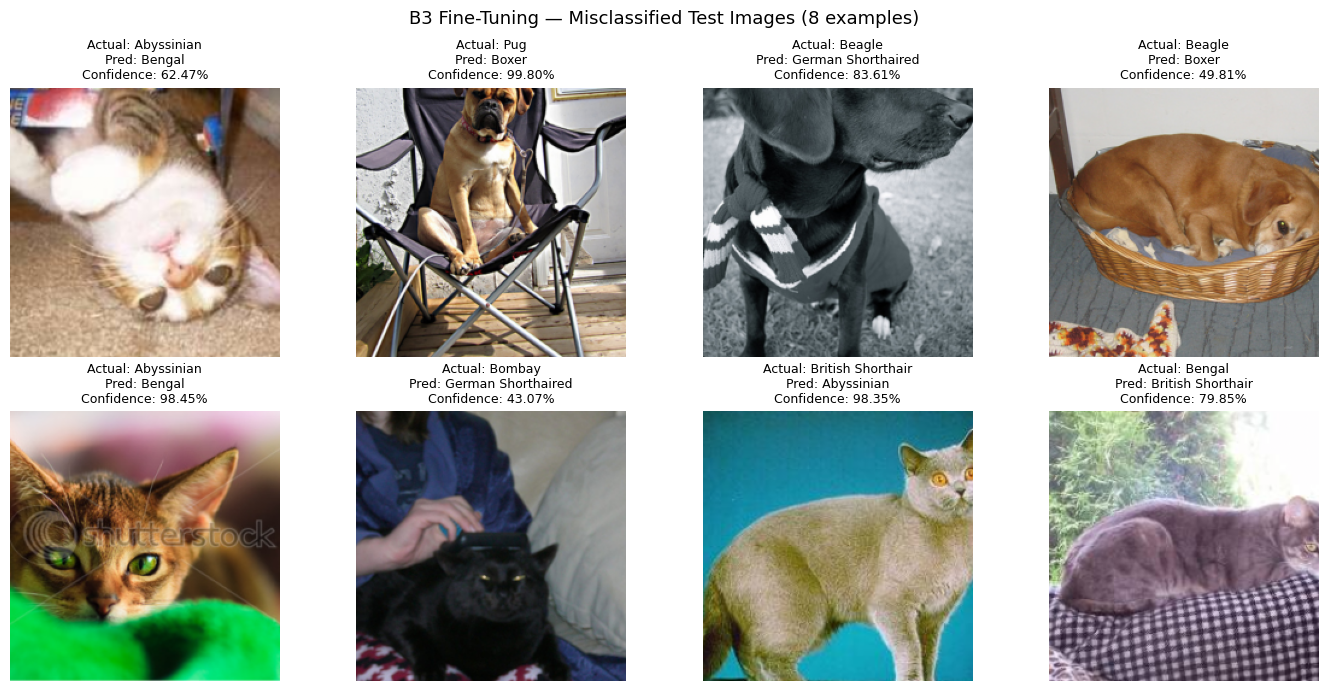

Total misklasifikasi B3: 8
Gambar tersimpan: /Users/ahmadrizkiw/Documents/Semester 5/Tugas05_VSCode_Notebook/results/B3_failure_analysis.png
CSV tersimpan: /Users/ahmadrizkiw/Documents/Semester 5/Tugas05_VSCode_Notebook/results/B3_misclassified.csv


,test_index,actual,predicted,confidence
0,15,Abyssinian,Bengal,0.624661
1,54,Pug,Boxer,0.997992
2,71,Beagle,German Shorthaired,0.836140
3,100,Beagle,Boxer,0.498136
4,127,Abyssinian,Bengal,0.984530
5,142,Bombay,German Shorthaired,0.430735
6,222,British Shorthair,Abyssinian,0.983547
7,275,Bengal,British Shorthair,0.798522


In [ ]:
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
checkpoint_path = CHECKPOINT_DIR / "B3_best.pth"
if not checkpoint_path.exists():
    raise FileNotFoundError(
        f"Checkpoint B3 tidak ditemukan: {checkpoint_path}\n"
        "Jalankan eksperimen B3 terlebih dahulu."
    )
model_b3 = build_model("B3").to(DEVICE)
checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE,
    weights_only=False
)
model_b3.load_state_dict(checkpoint["model_state_dict"])
model_b3.eval()
_, _, test_loader_b3 = make_loaders(augment=False)
wrong_samples = []
test_index = 0
mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
with torch.no_grad():
    for images, labels in test_loader_b3:
        images_device = images.to(DEVICE)
        labels_device = labels.to(DEVICE)
        logits = model_b3(images_device)
        probabilities = torch.softmax(logits, dim=1)
        confidences, predictions = probabilities.max(dim=1)
        for j in range(len(labels)):
            actual = int(labels[j].item())
            predicted = int(predictions[j].item())
            if actual != predicted:
                image = (images[j].cpu() * std + mean).clamp(0, 1)
                image = image.permute(1, 2, 0).numpy()
                wrong_samples.append({
                    "test_index": test_index,
                    "actual": CLASS_NAMES[actual],
                    "predicted": CLASS_NAMES[predicted],
                    "confidence": float(confidences[j].item()),
                    "image": image
                })
            test_index += 1
if not wrong_samples:
    print("Tidak ada misklasifikasi pada test set B3.")
else:
    csv_data = pd.DataFrame([
        {
            "test_index": sample["test_index"],
            "actual": sample["actual"],
            "predicted": sample["predicted"],
            "confidence": sample["confidence"]
        }
        for sample in wrong_samples
    ])
    csv_path = RESULTS_DIR / "B3_misclassified.csv"
    csv_data.to_csv(csv_path, index=False)
    selected = wrong_samples[:8]
    n = len(selected)
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    axes = axes.flatten()
    for ax in axes:
        ax.axis("off")
    for ax, sample in zip(axes, selected):
        ax.imshow(sample["image"])
        ax.set_title(
            f"Actual: {sample['actual']}\n"
            f"Pred: {sample['predicted']}\n"
            f"Confidence: {sample['confidence']:.2%}",
            fontsize=9
        )
        ax.axis("off")
    fig.suptitle(
        f"B3 Fine-Tuning — Misclassified Test Images ({n} examples)",
        fontsize=13
    )
    fig.tight_layout()
    output_path = RESULTS_DIR / "B3_failure_analysis.png"
    fig.savefig(output_path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Total misklasifikasi B3: {len(wrong_samples)}")
    print(f"Gambar tersimpan: {output_path}")
    print(f"CSV tersimpan: {csv_path}")
    display(csv_data.head(8))


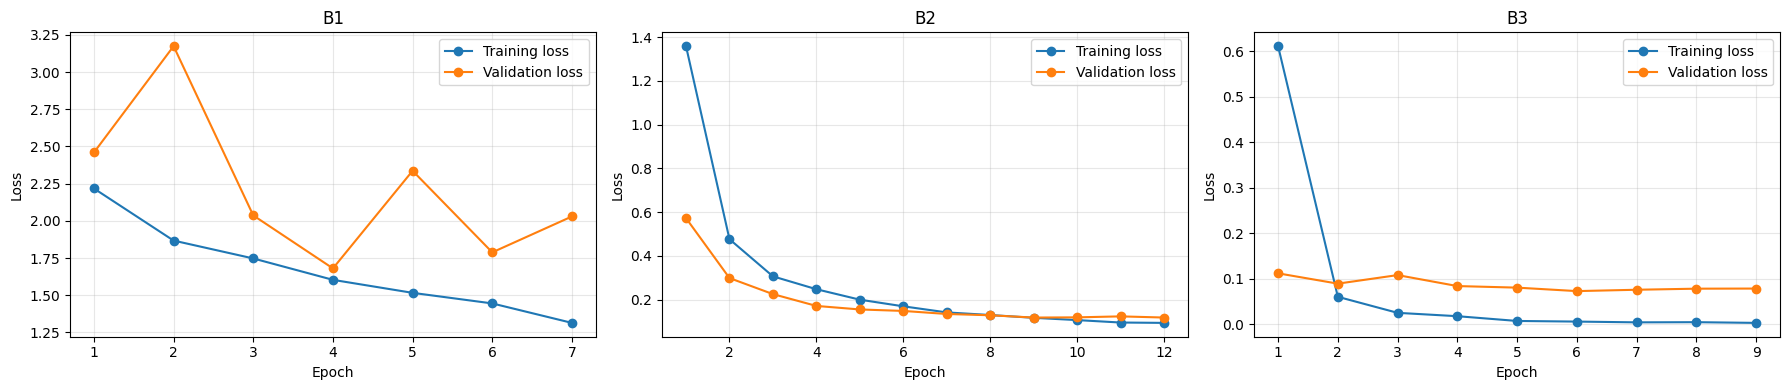

Files in results:
B1_classification_report.csv
B1_confusion_matrix.csv
B1_history.csv
B1_loss.png
B1_misclassified.csv
B2_classification_report.csv
B2_confusion_matrix.csv
B2_failure_analysis.png
B2_history.csv
B2_loss.png
B2_misclassified.csv
B3_classification_report.csv
B3_confusion_matrix.csv
B3_history.csv
B3_loss.png
B3_misclassified.csv
B4_Aug_classification_report.csv
B4_Aug_confusion_matrix.csv
B4_Aug_history.csv
B4_Aug_loss.png
B4_Aug_misclassified.csv
B4_NoAug_classification_report.csv
B4_NoAug_confusion_matrix.csv
B4_NoAug_history.csv
B4_NoAug_loss.png
B4_NoAug_misclassified.csv
B5_classification_report.csv
B5_confusion_matrix.csv
B5_history.csv
B5_loss.png
B5_misclassified.csv
C1_loss_curves_B1_B3.png
summary_metrics.csv
summary_metrics.json


In [11]:
make_required_loss_plot()
print("Files in results:")
for path in sorted(RESULTS_DIR.iterdir()):
    print(path.name)